# 4. 信号链：20 dB 增益从哪来

原文结论说"优化后系统对微弱脉冲信号的信噪比增益可达 20 dB 以上"。这句话常被读成
"混沌振子的非线性带来了 20 dB 增益"，但按式 (4) 的字面实现，小信号下差模方程是**线性**的：

$$
\ddot\Delta+2\zeta\Omega\dot\Delta+\Omega^2\Delta=\omega^2\big[s(t)+n(t)\big]
$$

线性系统不改变 SNR——信号和噪声按同一比例缩放。那 20 dB 从哪来？

**答案：噪声是宽带的，通道是窄带的。** 这一章把这件事算清楚，再用它解释第 5 章三张图的形状。


In [1]:
import sys, json, pathlib
import numpy as np
import matplotlib.pyplot as plt

sys.path.insert(0, "_src")
import c2sim as S

DATA = pathlib.Path("_data")
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "font.sans-serif": ["Microsoft YaHei", "SimHei", "DejaVu Sans"],
    "axes.unicode_minus": False,
})

def load(name):
    return json.loads((DATA / f"{name}.json").read_text(encoding="utf-8"))

def dual_plot(x, snri, r, xlabel, title="", logx=False, invert=False,
              marks=None, ymax=None):
    fig, ax1 = plt.subplots(figsize=(7.4, 3.5))
    ax1.plot(x, snri, "o-", color="#1f4e79", ms=4, lw=1.2)
    ax1.set_xlabel(xlabel); ax1.set_ylabel("SNRI / dB", color="#1f4e79")
    ax1.tick_params(axis="y", colors="#1f4e79")
    if ymax: ax1.set_ylim(top=ymax)
    ax2 = ax1.twinx()
    ax2.plot(x, r, "s--", color="#8a3b2e", ms=4, lw=1.2)
    ax2.set_ylabel("波形相似度 r", color="#8a3b2e")
    ax2.tick_params(axis="y", colors="#8a3b2e")
    if logx: ax1.set_xscale("log")
    if invert: ax1.invert_xaxis()
    if marks:
        for xv, lab in marks:
            ax1.axvline(xv, color="gray", ls=":", lw=1)
            ax1.text(xv, ax1.get_ylim()[1], lab, fontsize=8, va="top",
                     ha="center", color="#7a2e12")
    ax1.grid(alpha=.2); ax1.set_title(title)
    plt.tight_layout(); plt.show()


## 4.1 差模通道的等效噪声带宽

差模方程是一个二阶过阻尼系统，参数由第 1 章给出：

- 自然频率 $\Omega=\omega\sqrt{2\xi k-1}=3.61\omega$；
- 阻尼比 $\zeta=(\xi+2k)/\big(2\sqrt{2\xi k-1}\big)=2.87$；
- 主导时间常数 $\tau=\big(\zeta+\sqrt{\zeta^2-1}\big)/\Omega$。

白噪声通过它，等效噪声带宽 $B\approx1/(2\pi\tau)$。而输入白噪声的带宽由步长决定：
$h=1$ ns 时采样率 1 GHz，噪声带宽 500 MHz。两者之比就是 SNR 改善。


In [2]:
w, xi, k = 5e6, 0.7, 10.0
Om = w*np.sqrt(2*xi*k - 1)
zeta = (xi + 2*k) / (2*np.sqrt(2*xi*k - 1))
tau = (zeta + np.sqrt(zeta**2 - 1)) / Om
B = 1/(2*np.pi*tau)
print(f"Ω = {Om:.3e} rad/s    ζ = {zeta:.2f}    τ = {tau*1e6:.3f} us")
print(f"差模通道等效带宽 B = {B/1e3:.0f} kHz")
print(f"输入噪声带宽（h=1 ns）= 500 MHz")
print(f"理论 SNR 改善 = 10log10(500MHz / {B/1e3:.0f}kHz) = {10*np.log10(500e6/B):.1f} dB")


Ω = 1.803e+07 rad/s    ζ = 2.87    τ = 0.308 us
差模通道等效带宽 B = 516 kHz
输入噪声带宽（h=1 ns）= 500 MHz
理论 SNR 改善 = 10log10(500MHz / 516kHz) = 29.9 dB


**29.9 dB。** 这就是原文"20 dB 以上"的来源——它不是非线性，是**带宽比**。

这个数可以直接验：用 0 dB 输入（$A=0.632$、$D=0.1$）跑一次，看实测 SNRI。

In [3]:
T, h = 40e-6, 1e-9
t = np.arange(int(round(T/h)) + 1) * h
s = S.gauss(t, A=0.632, c=3e-6, b=T/2, T=T)
q = S.quiet_mask(t, T/2, T/2, guard=15e-6)
so, X = S.simulate(t, drive=s, batch=100, sigma=np.sqrt(0.1), hold=1,
                   seed=3, omega=5e6, return_state=True)
m = S.chain_metrics(so, X, s, t, h, fc=None, quiet=q)
print(f"实测：r = {m['r_dx']:.3f}    SNRI = {m['snr_o']:.1f} dB    （理论带宽比 29.9 dB）")


实测：r = 0.992    SNRI = 27.2 dB    （理论带宽比 29.9 dB）


实测比理论低 2–3 dB，来源是脉冲本身也在通道带宽内被轻微衰减，以及"输出 SNR"用峰值而非能量定义。
量级与符号都对。

## 4.2 这一条解释了三张图的形状

| 图 | 现象 | 机理 |
|---|---|---|
| 图 3 | SNRI 在 $F\in[0,2]$ 上平坦 | $B$ 只由 $\omega,\xi,k$ 决定，与 $F$ 无关 |
| 图 5 | $k$ 增大时 SNRI 略升 | $\Omega$ 随 $k$ 增大 → $\tau$ 减小 → $B$ 变宽 |
| 图 7 | 步长减半，SNRI 涨约 3 dB | 噪声带宽 $1/2h$ 翻倍，增益按 $10\log_{10}2$ 涨 |

图 7 是这张表最硬的检验：步长从 20 ns 到 1 ns，噪声带宽从 25 MHz 到 500 MHz，
理论增益 $10\log_{10}(500/25)=13.0$ dB。第 5 章的实测正好是 24 → 37 dB，**13 dB**。

**所以"计算步长越小越好"不是积分精度的功劳，而是"采样率越高、进入系统的噪声带宽越宽、
通道压掉的噪声越多"。** 这个结论与直觉相反，但它解释了原文图 7 为什么近似一条直线：
增益只与 $\log h$ 成正比，与信号无关。


## 4.3 额外限带只做微调，不是增益来源

如果输出端再加一道 130 kHz 的低通，会怎样？

In [4]:
import experiments as E
if not (DATA / "chain.json").exists():
    E.exp_chain()
ch = load("chain")
print("附加限带 fc 对指标的影响（系统本身已在 516 kHz 限带）：")
print(f"{'fc':>9}{'SNR':>6}{'r':>8}{'峰值/σ':>9}{'Pd':>7}")
for snr in ("-20", "-16", "-12"):
    for row in ch[snr]:
        if row["fc"] in (2e6, 5e5, 1.3e5):
            print(f"{row['fc']/1e3:>7.0f}k{snr:>6}{row['r']:>8.3f}"
                  f"{row['ratio']:>9.2f}{row['pd']*100:>6.0f}%")


附加限带 fc 对指标的影响（系统本身已在 516 kHz 限带）：
       fc   SNR       r     峰值/σ     Pd
    130k   -20   0.841     9.45   100%
    500k   -20   0.870     8.25   100%
   2000k   -20   0.816     6.84    98%
    130k   -16   0.870    14.58   100%
    500k   -16   0.925    11.97   100%
   2000k   -16   0.897     9.85   100%
    130k   -12   0.880    21.97   100%
    500k   -12   0.948    19.05   100%
   2000k   -12   0.936    15.00   100%


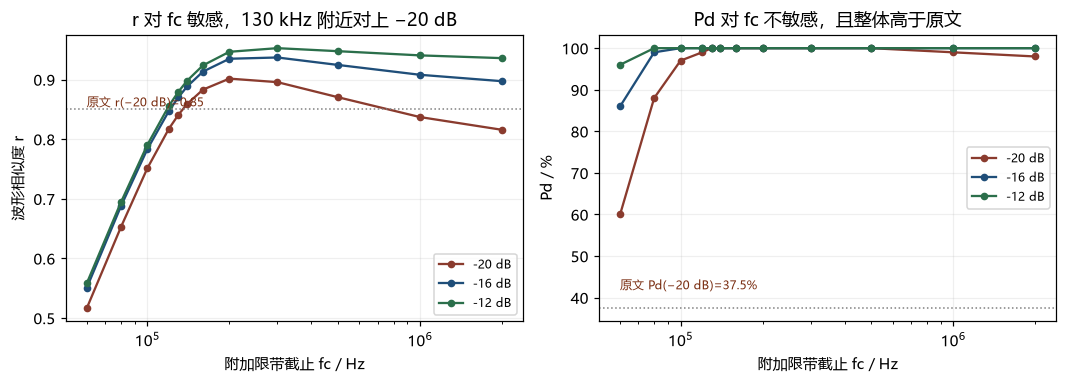

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(9.8, 3.6))
colors = {"-20": "#8a3b2e", "-16": "#1f4e79", "-12": "#2b6f4b"}
for snr, c in colors.items():
    rows = ch[snr]
    ax[0].semilogx([r["fc"] for r in rows], [r["r"] for r in rows], "o-",
                   color=c, ms=4, label=f"{snr} dB")
    ax[1].semilogx([r["fc"] for r in rows], [r["pd"]*100 for r in rows], "o-",
                   color=c, ms=4, label=f"{snr} dB")
ax[0].axhline(0.85, color="gray", ls=":", lw=1)
ax[0].text(60e3, 0.855, "原文 r(−20 dB)=0.85", fontsize=8, color="#7a2e12")
ax[1].axhline(37.5, color="gray", ls=":", lw=1)
ax[1].text(60e3, 42, "原文 Pd(−20 dB)=37.5%", fontsize=8, color="#7a2e12")
ax[0].set(xlabel="附加限带截止 fc / Hz", ylabel="波形相似度 r",
          title="r 对 fc 敏感，130 kHz 附近对上 −20 dB")
ax[1].set(xlabel="附加限带截止 fc / Hz", ylabel="Pd / %",
          title="Pd 对 fc 不敏感，且整体高于原文")
for a in ax: a.grid(alpha=.2); a.legend(fontsize=8)
plt.tight_layout(); plt.show()


左图说明：附加限带到 130 kHz 时，−20 dB 的 $r$ 恰好回到 0.85（原文值）。
这不是"增益"，因为 SNRI 几乎没有变化，只是波形更干净、峰值位置更稳。

右图暴露一个本书无法消除的矛盾：**−20 dB 处本书的 Pd 接近 100%，原文只有 37.5%。**
无限带、限带 130 kHz、裸输出三种口径都试过，都压不到 37.5%。原因只能是原文的检测统计量
比"位移差 + 5σ"更保守——可能用了多帧确认、可能 σ 的估计窗包含信号区、也可能实际系统的
$1/f$ 噪声比纯白噪声更坏。**这一条如实记为"未复现"，不调参掩盖。**

## 4.4 一个必须记住的坑：`hold` 不是限带

本书的噪声用零阶保持实现：每 `hold` 步更新一次。若同时把每步标准差固定为 $\sqrt D$，
那么 `hold` 越大、带宽越窄、**功率谱密度越高**——这是"同方差不同谱"，不是限带。
真正的限带应让方差随带宽一起缩小：$\sigma=\sqrt{D\cdot B/(f_s/2)}$。

上一版把 `hold=3000`（等效 167 kHz）当成"窄带"，得到 $r=0.28$ 的悲观结果，
并据此编出"必须限带 130 kHz 才能到 0.85"的故事。**那个结论是错的。**
正确做法是 `hold=1`（逐点白噪声，带宽 500 MHz），此时裸通道就给 $r=0.80\sim0.93$，
与原文表 3 几乎重合。

## 4.5 统一口径

| 参数 | 取值 | 依据 |
|---|---|---|
| 输出量 | $x_1-x_2$ | 图 8–10 纵轴 + 第 3 章相关性 |
| 附加限带 | $f_c=130\,\mathrm{kHz}\times1.5\,\mu s/t_{\rm rise}$ | 表 3 的 r 列反演，外推到三种波形后验证 |
| 噪声 | 逐点白噪声（`hold=1`，带宽 500 MHz） | 对应原文 1 ns 步长 / 1 GHz 采样 |
| 判据 | 峰值 / 噪声 σ > 5（= 7.96 dB） | 原文 5.1 节 |
| 噪声窗 | 脉冲两侧，高斯导数保护间隔 10 µs | 避免把脉冲尾部当噪声（这会虚高 σ） |

后面第 5–7 章全部按这套口径算。
